
# Learning Curve generation for: RPR × T × MFML

In this example we will demonstrate a full set of learning curves for the following
cases of single fidelity and multifidelity ML models. We will be using the KRR basic
architecture.

  Single-fidelity:              MFML:
    1. Isotropic                  5. MFML Isotropic
    2. RPR + Isotropic            6. MFML RPR + Isotropic
    3. Coupled T                  7. MFML Coupled T
    4. RPR + Coupled T            8. MFML RPR + Coupled T

X-axis: number of training samples at the highest fidelity.
MFML uses all 5 QeMFi fidelities with 2x scaling per level down.


## Imports



In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt

from mfml_qc.datasets import load_nitrophenol_data
from mfml_qc.representations import compute_flat_coulomb
from mfml_qc.utils import top_down_subsetting
from mfml_qc.vector_krr import VectorKRR, CoupledVectorKRR
from mfml_qc.rpr import RPRVectorKRR

## Load Data
We load the QeMFi nitrophenol dataset and split into a fixed test set of
1000 geometries and a training pool of the remaining 14000. The test set
uses the highest-fidelity (def2-TZVP) electronic dipole moments as
reference.



In [2]:
dataset = load_nitrophenol_data()
R = dataset["R"]
Z = dataset["Z"]
X_CM = dataset["X_CM"]
DPe = dataset["DPe"]

NUM_FIDS = 5
N_TEST = 1000

rng = np.random.RandomState(42)
perm = rng.permutation(len(R))
test_idx = perm[:N_TEST]
pool_idx = perm[N_TEST:]

DPe_test_ref = DPe[test_idx, -1, :]
X_test_flat = R[test_idx].reshape(N_TEST, -1)
CM_test = X_CM[test_idx]
CM_pool = X_CM[pool_idx]
R_pool = R[pool_idx]
DPe_pool = DPe[pool_idx]

## Configuration
We sweep over highest-fidelity training sizes from 16 to 256. Each model
variant is defined by a tuple of ``(name, use_rpr, use_T, is_mfml)``.
The ``eval_preds`` helper computes overall MAE, per-component MAE, cosine
similarity, and mean angular error.



In [3]:
N_HF_VALUES = [16, 32, 64, 128, 256]
KERNEL = "gaussian"
SIGMA = 250.0
REG = 1e-10


def eval_preds(pred, true):
    mae = np.mean(np.abs(pred - true))
    comp_mae = np.mean(np.abs(pred - true), axis=0)
    mag_p, mag_t = np.linalg.norm(pred, axis=-1), np.linalg.norm(true, axis=-1)
    dot = np.sum(pred * true, axis=-1)
    cos_sim = np.clip(dot / np.maximum(mag_p * mag_t, 1e-12), -1.0, 1.0)
    angle = np.mean(np.degrees(np.arccos(cos_sim)))
    return {
        "mae": mae,
        "comp_mae": comp_mae,
        "cos_sim": np.mean(cos_sim),
        "angle": angle,
        "pred": pred,
    }


def make_model(use_rpr, use_T):
    if use_T:
        inner = CoupledVectorKRR(
            kernel_type=KERNEL,
            sigma=SIGMA,
            reg=REG,
            val_fraction=0.15,
            max_opt_iter=200,
        )
    else:
        inner = VectorKRR(kernel_type=KERNEL, sigma=SIGMA, reg=REG)
    if use_rpr:
        return RPRVectorKRR(inner, Z, compute_flat_coulomb)
    return inner


# recall that the variants are labelled by (name, use_rpr, use_T, is_mfml)
VARIANTS = [
    ("Iso", False, False, False),
    ("RPR+Iso", True, False, False),
    ("T", False, True, False),
    ("RPR+T", True, True, False),
    ("MFML Iso", False, False, True),
    ("MFML RPR+Iso", True, False, True),
    ("MFML T", False, True, True),
    ("MFML RPR+T", True, True, True),
]

results = {v[0]: [] for v in VARIANTS}

## Single-Fidelity Models
Trains a single model on the ``n_hf`` highest-fidelity samples. Non-RPR
models receive pre-computed Coulomb matrices; RPR models receive flattened
Cartesian coordinates and compute canonicalized descriptors internally.



In [4]:
def run_single_fidelity(n_hf, use_rpr, use_T):
    Y_train = DPe_pool[:n_hf, -1, :]
    Y_mean = np.mean(Y_train, axis=0)
    model = make_model(use_rpr, use_T)
    if use_rpr:
        model.train(R_pool[:n_hf].reshape(n_hf, -1), Y_train - Y_mean)
        pred = model.predict(X_test_flat) + Y_mean
    else:
        model.train(CM_pool[:n_hf], Y_train - Y_mean)
        pred = model.predict(CM_test) + Y_mean
    return eval_preds(pred, DPe_test_ref)

## MFML Models
Trains 2N-1 = 9 sub-models following the SGCT scheme. The hierarchy uses
``n_hf`` samples at the highest fidelity and doubles at each lower level.
Upper sub-models learn fidelity-i targets on the fidelity-i subset; lower
sub-models learn fidelity-i targets on the fidelity-(i+1) subset.



In [5]:
def run_mfml(n_hf, use_rpr, use_T):
    n_trains = [
        min(n_hf * 2 ** (NUM_FIDS - 1 - i), len(R_pool)) for i in range(NUM_FIDS)
    ]

    y_trains_full = np.zeros(NUM_FIDS, dtype=object)
    indexes_full = np.zeros(NUM_FIDS, dtype=object)
    for i in range(NUM_FIDS):
        vals = DPe_pool[:, i, :]
        y_trains_full[i] = vals - np.mean(vals, axis=0)
        indexes_full[i] = np.column_stack(
            [np.arange(len(R_pool)), np.arange(len(R_pool))]
        )

    subset_y, subset_idx = top_down_subsetting(
        y_trains_full, indexes_full, n_trains, seed=42
    )

    n_sub = 2 * NUM_FIDS - 1
    sub_X, sub_Y, sub_Y_mean = [], [], []

    for i in range(NUM_FIDS):
        idx_i = subset_idx[i][:, 0]
        Y_i = DPe_pool[idx_i, i, :]
        m_i = np.mean(Y_i, axis=0)
        sub_Y.append(Y_i - m_i)
        sub_Y_mean.append(m_i)
        sub_X.append(
            R_pool[idx_i].reshape(len(idx_i), -1) if use_rpr else CM_pool[idx_i]
        )

    for i in range(NUM_FIDS - 1):
        idx_ip1 = subset_idx[i + 1][:, 0]
        Y_lower = DPe_pool[idx_ip1, i, :]
        m_i = np.mean(Y_lower, axis=0)
        sub_Y.append(Y_lower - m_i)
        sub_Y_mean.append(m_i)
        sub_X.append(
            R_pool[idx_ip1].reshape(len(idx_ip1), -1) if use_rpr else CM_pool[idx_ip1]
        )

    sub_models = []
    for s in range(n_sub):
        model_s = make_model(use_rpr, use_T)
        model_s.train(sub_X[s], sub_Y[s])
        sub_models.append(model_s)

    X_pred = X_test_flat if use_rpr else CM_test
    pred = np.zeros((N_TEST, 3))
    for i in range(NUM_FIDS):
        pred += sub_models[i].predict(X_pred) + sub_Y_mean[i]
    for i in range(NUM_FIDS - 1):
        pred -= sub_models[NUM_FIDS + i].predict(X_pred) + sub_Y_mean[NUM_FIDS + i]

    return eval_preds(pred, DPe_test_ref)

## Run All Variants
For each highest-fidelity training size, all 8 variants are trained and
evaluated. Results are stored in a dictionary keyed by variant name.



In [6]:
for n_hf in N_HF_VALUES:
    for name, use_rpr, use_T, is_mfml in VARIANTS:
        r = (
            run_mfml(n_hf, use_rpr, use_T)
            if is_mfml
            else run_single_fidelity(n_hf, use_rpr, use_T)
        )
        results[name].append(r)

## Overall MAE and Angular Error Learning Curves
Dashed lines represent single-fidelity models; solid lines represent MFML.
Colour encodes the (RPR, T) combination. The left panel shows overall MAE
on a log-log scale; the right panel shows mean angular error.



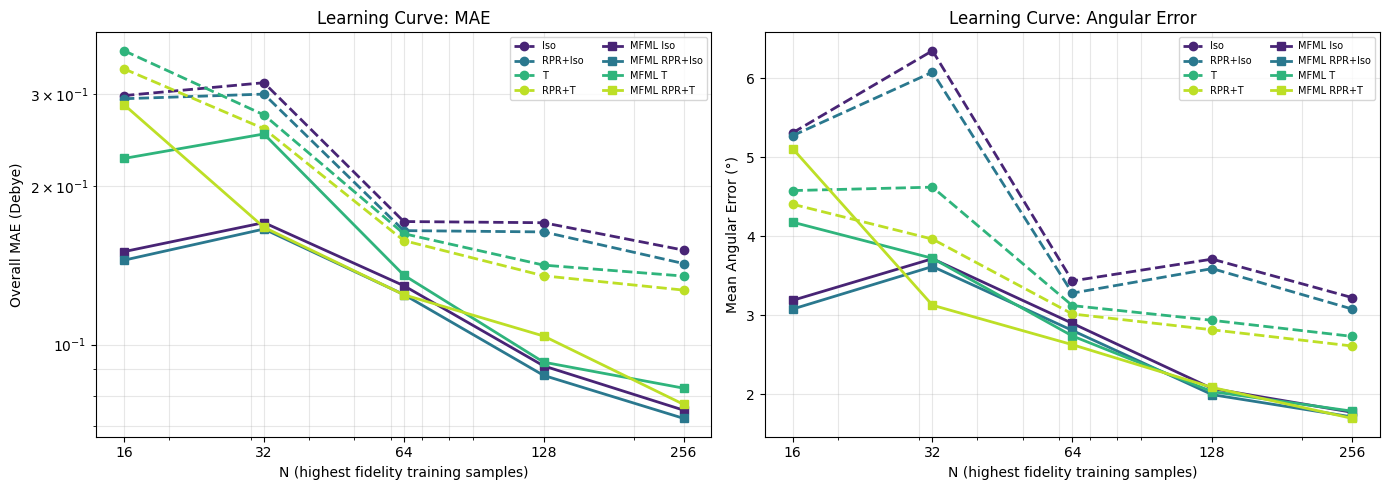

In [7]:
combo_colors = {
    "Iso": plt.cm.viridis(0.1),
    "RPR+Iso": plt.cm.viridis(0.4),
    "T": plt.cm.viridis(0.65),
    "RPR+T": plt.cm.viridis(0.9),
}


def _base_key(use_rpr, use_T):
    return ("RPR+" if use_rpr else "") + ("T" if use_T else "Iso")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for name, use_rpr, use_T, is_mfml in VARIANTS:
    maes = [results[name][i]["mae"] for i in range(len(N_HF_VALUES))]
    angles = [results[name][i]["angle"] for i in range(len(N_HF_VALUES))]
    color = combo_colors[_base_key(use_rpr, use_T)]
    ls = "-" if is_mfml else "--"
    marker = "s" if is_mfml else "o"
    ax1.loglog(
        N_HF_VALUES,
        maes,
        marker=marker,
        linestyle=ls,
        color=color,
        lw=2,
        ms=6,
        label=name,
    )
    ax2.semilogx(
        N_HF_VALUES,
        angles,
        marker=marker,
        linestyle=ls,
        color=color,
        lw=2,
        ms=6,
        label=name,
    )

for ax, ylabel, title in [
    (ax1, "Overall MAE (Debye)", "Learning Curve: MAE"),
    (ax2, "Mean Angular Error (°)", "Learning Curve: Angular Error"),
]:
    ax.set_xlabel("N (highest fidelity training samples)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=7, ncol=2)
    ax.grid(True, alpha=0.3, which="both")
    ax.set_xticks(N_HF_VALUES)
    ax.set_xticklabels([str(n) for n in N_HF_VALUES])

plt.tight_layout()
plt.show()

## Per-Component Learning Curves
The same learning curves broken down by dipole component (μ_x, μ_y, μ_z).
This reveals which components benefit most from RPR, coupled T, or MFML.
Unlike the last example, we DO NOT train individual component-wise MFML models
but only look at the separate components post hoc.



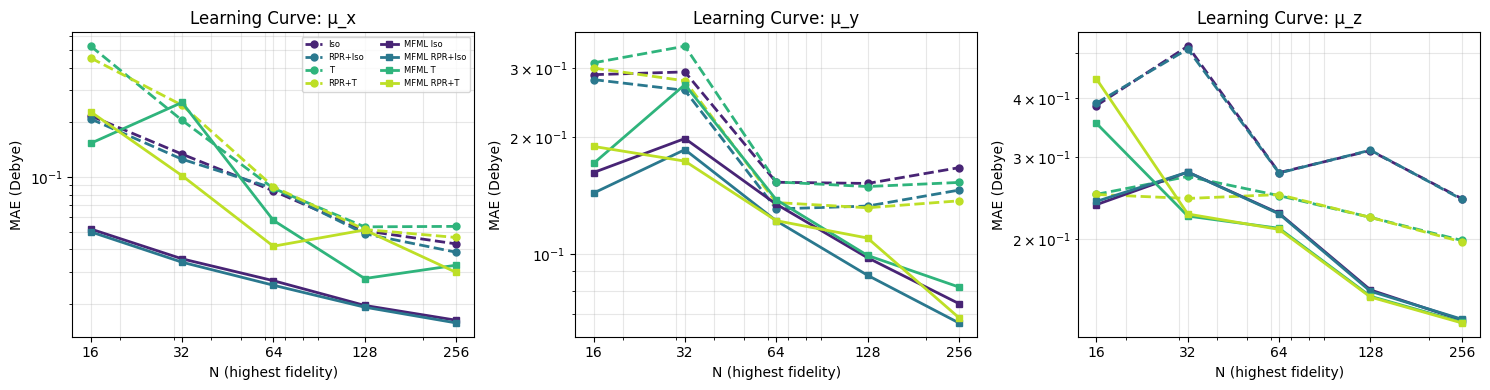

In [8]:
comp_labels = ["μ_x", "μ_y", "μ_z"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for c in range(3):
    for name, use_rpr, use_T, is_mfml in VARIANTS:
        vals = [results[name][i]["comp_mae"][c] for i in range(len(N_HF_VALUES))]
        color = combo_colors[_base_key(use_rpr, use_T)]
        ls = "-" if is_mfml else "--"
        marker = "s" if is_mfml else "o"
        axes[c].loglog(
            N_HF_VALUES,
            vals,
            marker=marker,
            linestyle=ls,
            color=color,
            lw=2,
            ms=5,
            label=name,
        )
    axes[c].set_xlabel("N (highest fidelity)")
    axes[c].set_ylabel("MAE (Debye)")
    axes[c].set_title(f"Learning Curve: {comp_labels[c]}")
    axes[c].grid(True, alpha=0.3, which="both")
    axes[c].set_xticks(N_HF_VALUES)
    axes[c].set_xticklabels([str(n) for n in N_HF_VALUES])
    if c == 0:
        axes[c].legend(fontsize=6, ncol=2)

plt.tight_layout()
plt.show()

## Parity Plots at Largest N_hf
Predicted vs. reference dipole components for all 8 variants at the largest
training size. Points are coloured by the true dipole magnitude. Each row
corresponds to one model variant; columns are the three Cartesian components.



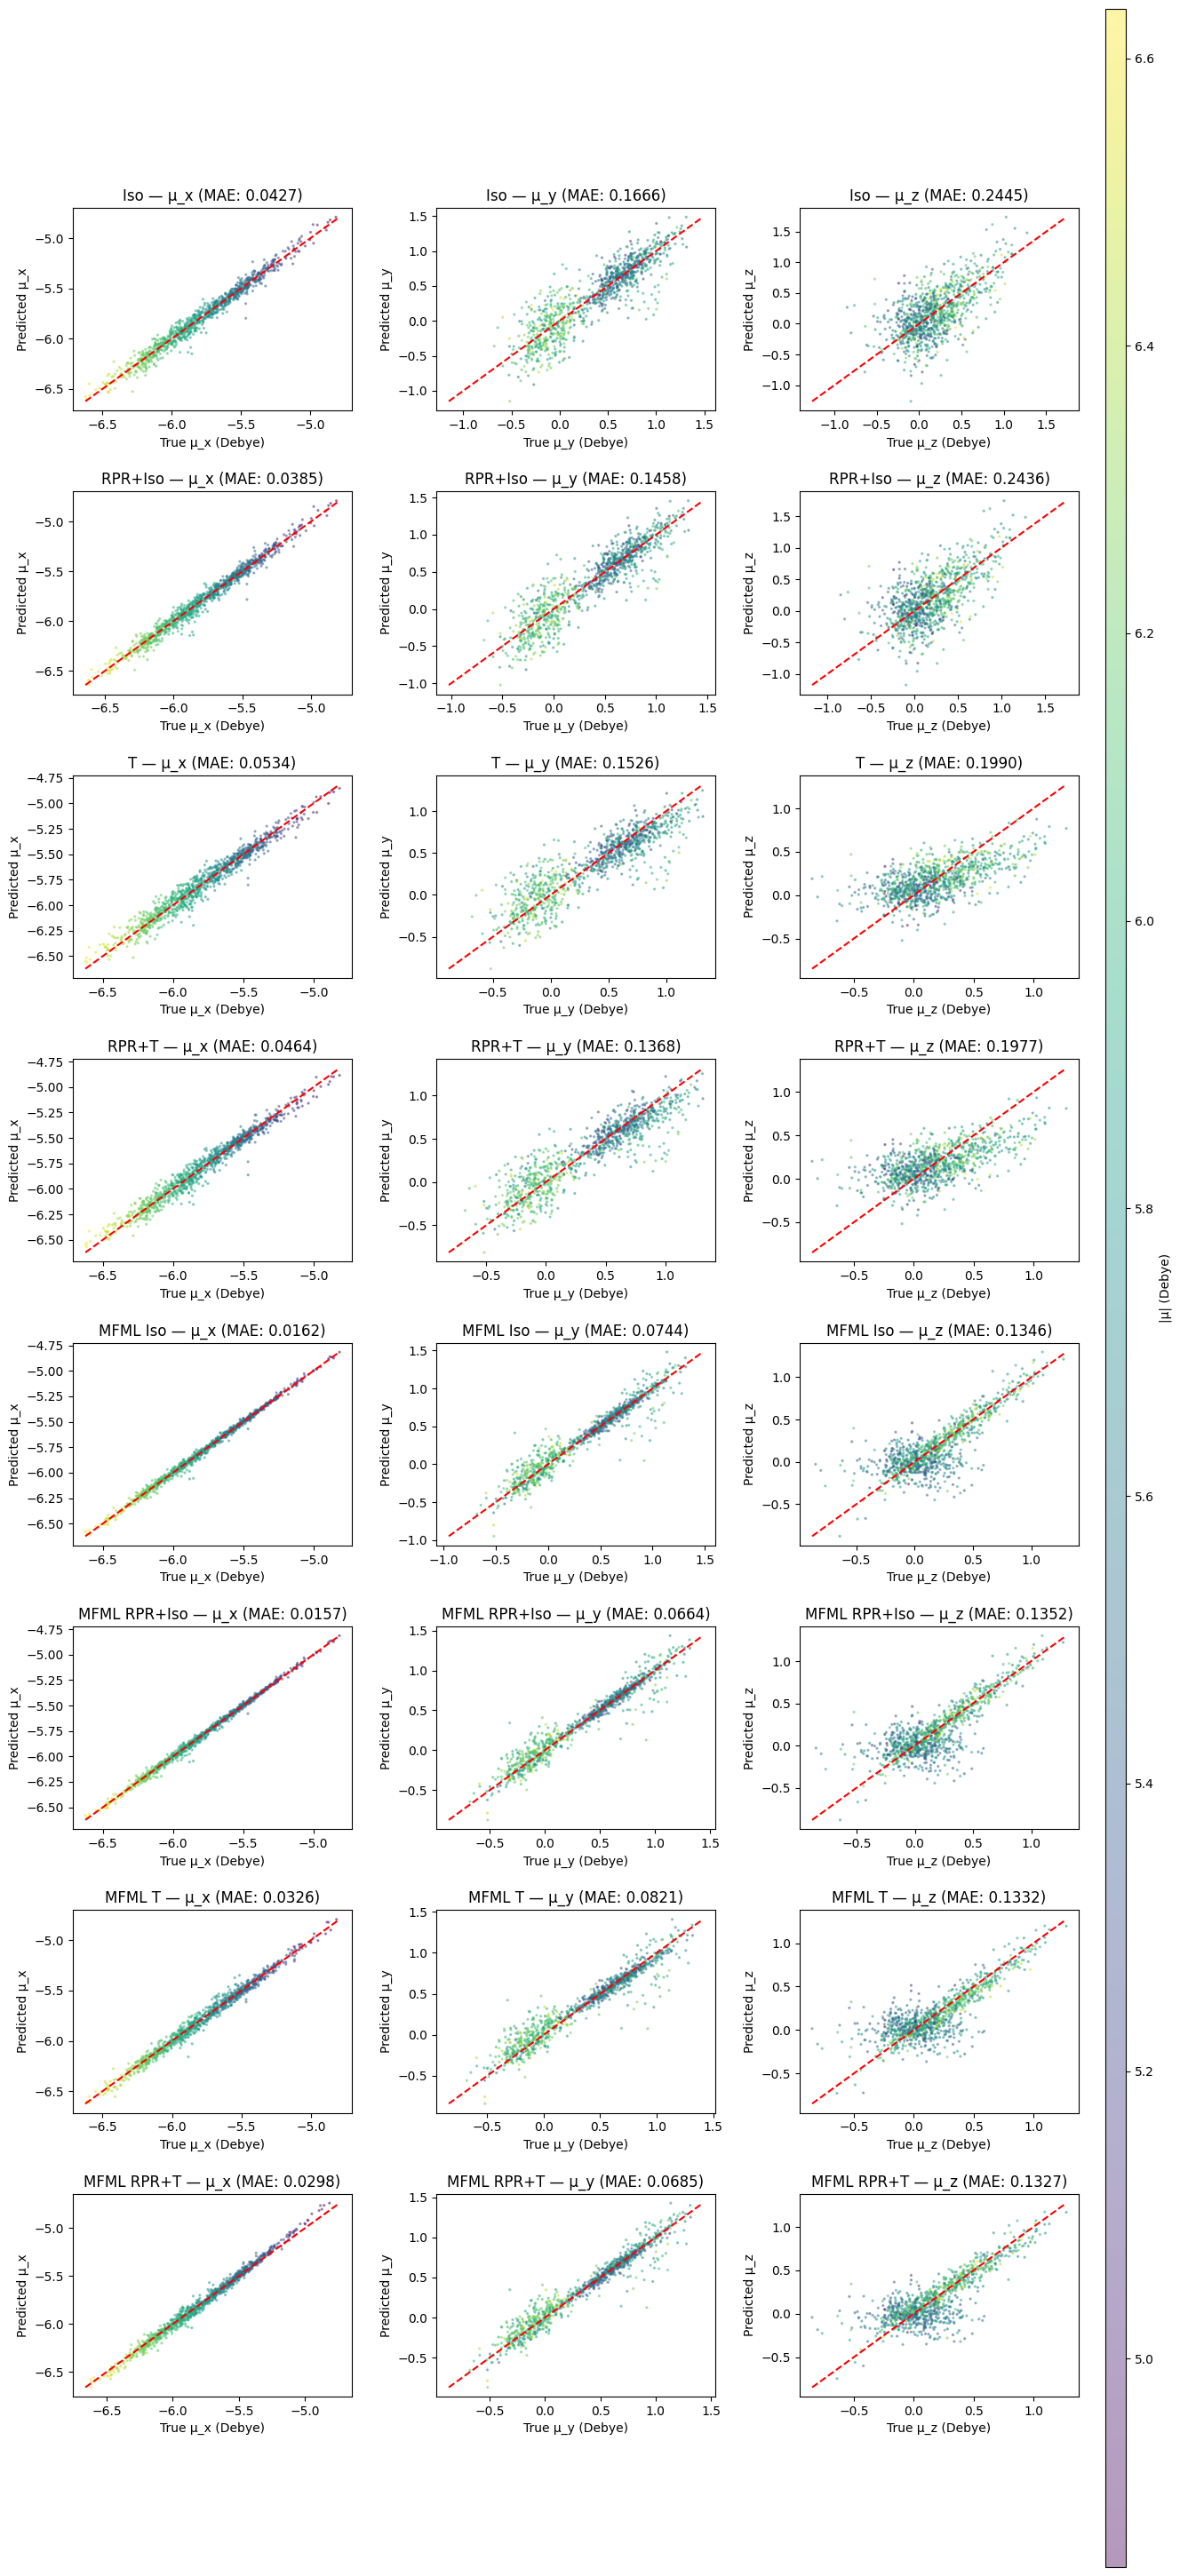

In [9]:
n_hf_last = N_HF_VALUES[-1]
mag_true = np.linalg.norm(DPe_test_ref, axis=-1)
cmap = plt.cm.viridis
vmin, vmax = mag_true.min(), mag_true.max()

fig, axes = plt.subplots(
    len(VARIANTS),
    3,
    figsize=(5 * 3, 4 * len(VARIANTS)),
    gridspec_kw={"hspace": 0.4, "wspace": 0.3},
)

for row, (name, _, _, _) in enumerate(VARIANTS):
    pred = results[name][-1]["pred"]
    comp_mae = np.mean(np.abs(pred - DPe_test_ref), axis=0)
    for c in range(3):
        sc = axes[row, c].scatter(
            DPe_test_ref[:, c],
            pred[:, c],
            s=2,
            alpha=0.4,
            c=mag_true,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
        )
        lo = min(DPe_test_ref[:, c].min(), pred[:, c].min())
        hi = max(DPe_test_ref[:, c].max(), pred[:, c].max())
        axes[row, c].plot([lo, hi], [lo, hi], "r--", lw=1.5)
        axes[row, c].set_xlabel(f"True {comp_labels[c]} (Debye)")
        axes[row, c].set_ylabel(f"Predicted {comp_labels[c]}")
        axes[row, c].set_title(f"{name} — {comp_labels[c]} (MAE: {comp_mae[c]:.4f})")

fig.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.05, 0.015, 0.9])
fig.colorbar(sc, cax=cbar_ax).set_label("|μ| (Debye)")
plt.show()